In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, 
    classification_report, precision_score, recall_score, f1_score
)
import joblib
import warnings
warnings.filterwarnings('ignore')

# Configuración
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("=" * 80)
print("CHURN PREDICTION - MODELING")
print("=" * 80)

# Cargar datos procesados
train = pd.read_csv('../data/processed/train_data.csv')
val = pd.read_csv('../data/processed/val_data.csv')
test = pd.read_csv('../data/processed/test_data.csv')

print(f"\nTrain: {train.shape}")
print(f"Validation: {val.shape}")
print(f"Test: {test.shape}")

CHURN PREDICTION - MODELING

Train: (9554, 12)
Validation: (2000, 12)
Test: (2000, 12)


In [2]:
print("\n1. PREPARAR DATOS PARA MODELADO")

# Separar features y target
X_train = train.drop('Exited', axis=1)
y_train = train['Exited']

X_val = val.drop('Exited', axis=1)
y_val = val['Exited']

X_test = test.drop('Exited', axis=1)
y_test = test['Exited']

print(f"\nX_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"\nFeatures: {X_train.columns.tolist()}")

# Verificar balanceo
print(f"\nDistribución target en train (SMOTE aplicado):")
print(y_train.value_counts())


1. PREPARAR DATOS PARA MODELADO

X_train: (9554, 11)
y_train: (9554,)

Features: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain']

Distribución target en train (SMOTE aplicado):
Exited
0    4777
1    4777
Name: count, dtype: int64


In [3]:
print("\n2. ENTRENAMIENTO - MODELO BASELINE (LOGISTIC REGRESSION)")

# Entrenar
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predicciones
y_train_pred_lr = lr_model.predict(X_train)
y_val_pred_lr = lr_model.predict(X_val)
y_test_pred_lr = lr_model.predict(X_test)

# Probabilidades (necesarias para AUC)
y_train_proba_lr = lr_model.predict_proba(X_train)[:, 1]
y_val_proba_lr = lr_model.predict_proba(X_val)[:, 1]
y_test_proba_lr = lr_model.predict_proba(X_test)[:, 1]

# Evaluar
train_auc_lr = roc_auc_score(y_train, y_train_proba_lr)
val_auc_lr = roc_auc_score(y_val, y_val_proba_lr)
test_auc_lr = roc_auc_score(y_test, y_test_proba_lr)

print(f"\nLogistic Regression:")
print(f"Train AUC: {train_auc_lr:.4f}")
print(f"Validation AUC: {val_auc_lr:.4f}")
print(f"Test AUC: {test_auc_lr:.4f}")

# Guardar resultados
lr_results = {
    'model': 'Logistic Regression',
    'train_auc': train_auc_lr,
    'val_auc': val_auc_lr,
    'test_auc': test_auc_lr
}
print(f"\n✅ Modelo entrenado y evaluado")


2. ENTRENAMIENTO - MODELO BASELINE (LOGISTIC REGRESSION)

Logistic Regression:
Train AUC: 0.8081
Validation AUC: 0.7604
Test AUC: 0.7656

✅ Modelo entrenado y evaluado


In [4]:
print("\n3. ENTRENAMIENTO - RANDOM FOREST")

# Entrenar
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# Predicciones
y_train_pred_rf = rf_model.predict(X_train)
y_val_pred_rf = rf_model.predict(X_val)
y_test_pred_rf = rf_model.predict(X_test)

# Probabilidades
y_train_proba_rf = rf_model.predict_proba(X_train)[:, 1]
y_val_proba_rf = rf_model.predict_proba(X_val)[:, 1]
y_test_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluar
train_auc_rf = roc_auc_score(y_train, y_train_proba_rf)
val_auc_rf = roc_auc_score(y_val, y_val_proba_rf)
test_auc_rf = roc_auc_score(y_test, y_test_proba_rf)

print(f"\nRandom Forest:")
print(f"Train AUC: {train_auc_rf:.4f}")
print(f"Validation AUC: {val_auc_rf:.4f}")
print(f"Test AUC: {test_auc_rf:.4f}")

rf_results = {
    'model': 'Random Forest',
    'train_auc': train_auc_rf,
    'val_auc': val_auc_rf,
    'test_auc': test_auc_rf
}
print(f"\n✅ Modelo entrenado y evaluado")


3. ENTRENAMIENTO - RANDOM FOREST

Random Forest:
Train AUC: 0.9945
Validation AUC: 0.8525
Test AUC: 0.8531

✅ Modelo entrenado y evaluado


In [5]:
print("\n4. ENTRENAMIENTO - XGBOOST")

# Entrenar
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='auc'
)
xgb_model.fit(X_train, y_train)

# Predicciones
y_train_pred_xgb = xgb_model.predict(X_train)
y_val_pred_xgb = xgb_model.predict(X_val)
y_test_pred_xgb = xgb_model.predict(X_test)

# Probabilidades
y_train_proba_xgb = xgb_model.predict_proba(X_train)[:, 1]
y_val_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]
y_test_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Evaluar
train_auc_xgb = roc_auc_score(y_train, y_train_proba_xgb)
val_auc_xgb = roc_auc_score(y_val, y_val_proba_xgb)
test_auc_xgb = roc_auc_score(y_test, y_test_proba_xgb)

print(f"\nXGBoost:")
print(f"Train AUC: {train_auc_xgb:.4f}")
print(f"Validation AUC: {val_auc_xgb:.4f}")
print(f"Test AUC: {test_auc_xgb:.4f}")

xgb_results = {
    'model': 'XGBoost',
    'train_auc': train_auc_xgb,
    'val_auc': val_auc_xgb,
    'test_auc': test_auc_xgb
}
print(f"\n✅ Modelo entrenado y evaluado")


4. ENTRENAMIENTO - XGBOOST

XGBoost:
Train AUC: 0.9807
Validation AUC: 0.8572
Test AUC: 0.8595

✅ Modelo entrenado y evaluado


In [6]:
print("\n5. ENTRENAMIENTO - LIGHTGBM")

# Entrenar
lgb_model = LGBMClassifier(
    n_estimators=100,
    max_depth=7,
    learning_rate=0.1,
    num_leaves=31,
    random_state=42,
    verbose=-1
)
lgb_model.fit(X_train, y_train)

# Predicciones
y_train_pred_lgb = lgb_model.predict(X_train)
y_val_pred_lgb = lgb_model.predict(X_val)
y_test_pred_lgb = lgb_model.predict(X_test)

# Probabilidades
y_train_proba_lgb = lgb_model.predict_proba(X_train)[:, 1]
y_val_proba_lgb = lgb_model.predict_proba(X_val)[:, 1]
y_test_proba_lgb = lgb_model.predict_proba(X_test)[:, 1]

# Evaluar
train_auc_lgb = roc_auc_score(y_train, y_train_proba_lgb)
val_auc_lgb = roc_auc_score(y_val, y_val_proba_lgb)
test_auc_lgb = roc_auc_score(y_test, y_test_proba_lgb)

print(f"\nLightGBM:")
print(f"Train AUC: {train_auc_lgb:.4f}")
print(f"Validation AUC: {val_auc_lgb:.4f}")
print(f"Test AUC: {test_auc_lgb:.4f}")

lgb_results = {
    'model': 'LightGBM',
    'train_auc': train_auc_lgb,
    'val_auc': val_auc_lgb,
    'test_auc': test_auc_lgb
}
print(f"\n✅ Modelo entrenado y evaluado")


5. ENTRENAMIENTO - LIGHTGBM

LightGBM:
Train AUC: 0.9825
Validation AUC: 0.8541
Test AUC: 0.8579

✅ Modelo entrenado y evaluado


In [7]:
print("\n6. COMPARACIÓN DE MODELOS")

# Crear DataFrame de resultados
results_df = pd.DataFrame([
    lr_results,
    rf_results,
    xgb_results,
    lgb_results
])

print("\n" + "=" * 80)
print("RESUMEN DE MODELOS")
print("=" * 80)
print(results_df.to_string(index=False))

# Mejor modelo
best_model_idx = results_df['test_auc'].idxmax()
best_model_name = results_df.loc[best_model_idx, 'model']
best_model_auc = results_df.loc[best_model_idx, 'test_auc']

print(f"\n🏆 MEJOR MODELO: {best_model_name}")
print(f"Test AUC: {best_model_auc:.4f}")


6. COMPARACIÓN DE MODELOS

RESUMEN DE MODELOS
              model  train_auc  val_auc  test_auc
Logistic Regression   0.808082 0.760429  0.765584
      Random Forest   0.994516 0.852484  0.853073
            XGBoost   0.980694 0.857238  0.859548
           LightGBM   0.982473 0.854150  0.857924

🏆 MEJOR MODELO: XGBoost
Test AUC: 0.8595


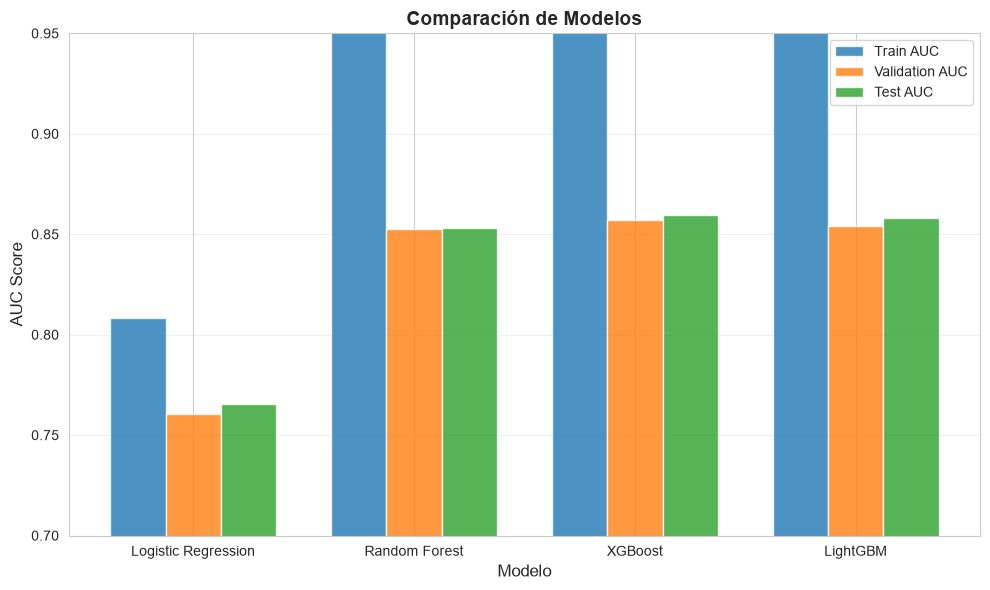

✅ Gráfico de comparación creado


In [8]:
# Gráfico de comparación
fig, ax = plt.subplots(figsize=(10, 6))

models = results_df['model']
x = np.arange(len(models))
width = 0.25

ax.bar(x - width, results_df['train_auc'], width, label='Train AUC', alpha=0.8)
ax.bar(x, results_df['val_auc'], width, label='Validation AUC', alpha=0.8)
ax.bar(x + width, results_df['test_auc'], width, label='Test AUC', alpha=0.8)

ax.set_xlabel('Modelo', fontsize=12)
ax.set_ylabel('AUC Score', fontsize=12)
ax.set_title('Comparación de Modelos', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.set_ylim([0.7, 0.95])
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Gráfico de comparación creado")

In [9]:
print("\n7. EVALUACIÓN DETALLADA DEL MEJOR MODELO (XGBoost)")

# Usar XGBoost como mejor modelo
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Métricas
auc = roc_auc_score(y_test, y_proba_xgb)
precision = precision_score(y_test, y_pred_xgb)
recall = recall_score(y_test, y_pred_xgb)
f1 = f1_score(y_test, y_pred_xgb)

print(f"\nMÉTRICAS EN TEST SET:")
print(f"ROC-AUC:   {auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_xgb)
print(f"\nMATRIZ DE CONFUSIÓN:")
print(cm)

# Classification report
print(f"\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_xgb))


7. EVALUACIÓN DETALLADA DEL MEJOR MODELO (XGBoost)

MÉTRICAS EN TEST SET:
ROC-AUC:   0.8595
Precision: 0.6559
Recall:    0.5995
F1-Score:  0.6264

MATRIZ DE CONFUSIÓN:
[[1465  128]
 [ 163  244]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1593
           1       0.66      0.60      0.63       407

    accuracy                           0.85      2000
   macro avg       0.78      0.76      0.77      2000
weighted avg       0.85      0.85      0.85      2000



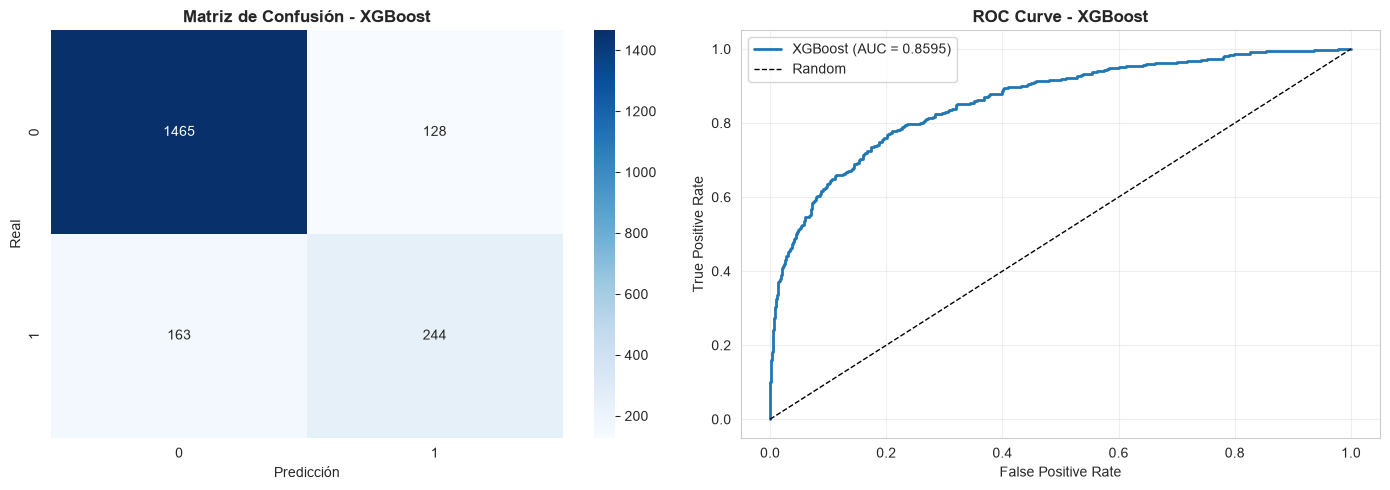

✅ Visualizaciones creadas


In [10]:
# Matriz de confusión
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de confusión
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - XGBoost', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba_xgb)
axes[1].plot(fpr, tpr, label=f'XGBoost (AUC = {auc:.4f})', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k--', label='Random', linewidth=1)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve - XGBoost', fontsize=12, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Visualizaciones creadas")


8. IMPORTANCIA DE FEATURES

Top 10 Features más importantes:
              feature  importance
5       NumOfProducts    0.225694
9   Geography_Germany    0.193497
2                 Age    0.133502
7      IsActiveMember    0.117981
1              Gender    0.116320
3              Tenure    0.069718
4             Balance    0.044709
10    Geography_Spain    0.037195
0         CreditScore    0.020863
8     EstimatedSalary    0.020345


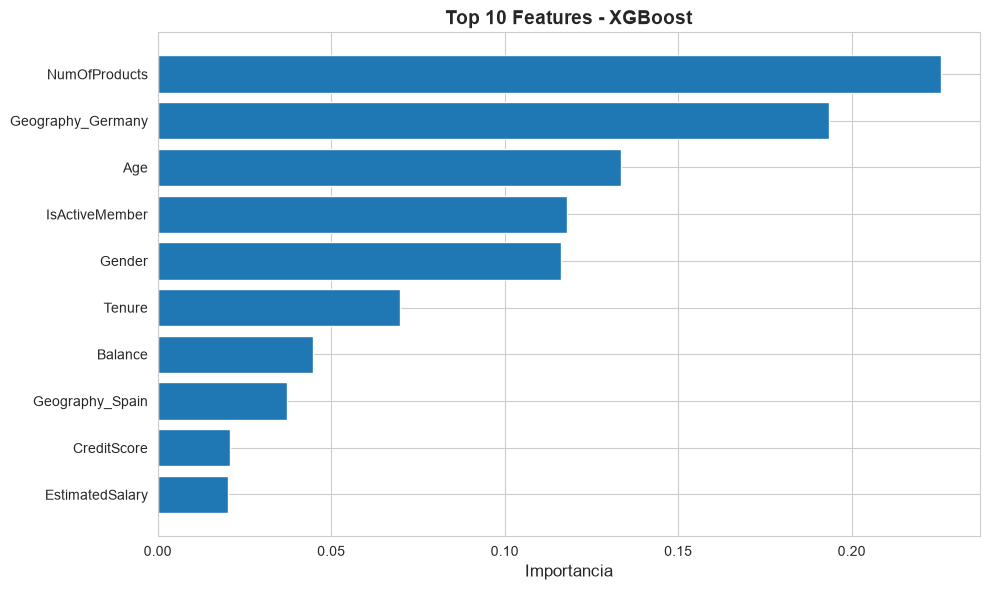

✅ Feature importance visualizado


In [11]:
print("\n8. IMPORTANCIA DE FEATURES")

# Feature importance
feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 10 Features más importantes:")
print(feature_importance.head(10))

# Visualizar
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['feature'][:10], feature_importance['importance'][:10])
plt.xlabel('Importancia', fontsize=12)
plt.title('Top 10 Features - XGBoost', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("✅ Feature importance visualizado")

In [12]:
print("\n9. GUARDAR MODELO")

# Guardar modelo XGBoost
joblib.dump(xgb_model, '../models/xgboost_model.pkl')
print("✅ Modelo XGBoost guardado en: ../models/xgboost_model.pkl")

# Guardar datos de test para próximas fases
X_test.to_csv('../data/processed/X_test.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)
print("✅ X_test y y_test guardados")

# Guardar predicciones
predictions = pd.DataFrame({
    'actual': y_test,
    'predicted': y_pred_xgb,
    'probability': y_proba_xgb
})
predictions.to_csv('../data/processed/predictions.csv', index=False)
print("✅ Predicciones guardadas")


9. GUARDAR MODELO
✅ Modelo XGBoost guardado en: ../models/xgboost_model.pkl
✅ X_test y y_test guardados
✅ Predicciones guardadas
